In [1]:
# This cell is mandatory in all Dymos documentation notebooks.
missing_packages = []
try:
    import openmdao.api as om  # noqa: F401
except ImportError:
    if 'google.colab' in str(get_ipython()):
        !python -m pip install openmdao[notebooks]
    else:
        missing_packages.append('openmdao')
try:
    import dymos as dm  # noqa: F401
except ImportError:
    if 'google.colab' in str(get_ipython()):
        !python -m pip install dymos
    else:
        missing_packages.append('dymos')
try:
    import pyoptsparse  # noqa: F401
except ImportError:
    if 'google.colab' in str(get_ipython()):
        !pip install -q condacolab
        import condacolab
        condacolab.install_miniconda()
        !conda install -c conda-forge pyoptsparse
    else:
        missing_packages.append('pyoptsparse')
if missing_packages:
    raise EnvironmentError('This notebook requires the following packages '
                           'please install them and restart this notebook\'s runtime: {",".join(missing_packages)}')

# The Brachistochrone with Externally-Sourced Controls

```{admonition} Things you'll learn through this example
- How to provide trajectory control values from an external source.
```

This example is the same as the other brachistochrone example with one exception:  the control values come from an external source upstream of the trajectory.

The following script fully defines the brachistochrone problem with Dymos and solves it.
A new `IndepVarComp` is added before the trajectory.
The transcription used in the relevant phase is defined first so that we can obtain the number of control input nodes.
The IndepVarComp then provides the control $\theta$ at the correct number of nodes, and sends them to the trajectory.
Since the control values are no longer managed by Dymos, they are added as design variables using the OpenMDAO `add_design_var` method.

In [2]:
om.display_source("dymos.examples.brachistochrone.brachistochrone_ode")

import numpy as np
import openmdao.api as om


class BrachistochroneODE(om.ExplicitComponent):

    def initialize(self):
        self.options.declare('num_nodes', types=int)
        self.options.declare('static_gravity', types=(bool,), default=False,
                             desc='If True, treat gravity as a static (scalar) input, rather than '
                                  'having different values at each node.')

    def setup(self):
        nn = self.options['num_nodes']

        # Inputs
        self.add_input('v', val=np.zeros(nn), desc='velocity', units='m/s')

        if self.options['static_gravity']:
            self.add_input('g', val=9.80665, desc='grav. acceleration', units='m/s/s',
                           tags=['dymos.static_target'])
        else:
            self.add_input('g', val=9.80665 * np.ones(nn), desc='grav. acceleration', units='m/s/s')

        self.add_input('theta', val=np.ones(nn), desc='angle of wire', units='rad')

        self.add_output('xdot', val=np.zeros(nn), desc='velocity component in x', units='m/s',
                        tags=['dymos.state_rate_source:x', 'dymos.state_units:m'])

        self.add_output('ydot', val=np.zeros(nn), desc='velocity component in y', units='m/s',
                        tags=['dymos.state_rate_source:y', 'dymos.state_units:m'])

        self.add_output('vdot', val=np.zeros(nn), desc='acceleration magnitude', units='m/s**2',
                        tags=['dymos.state_rate_source:v', 'dymos.state_units:m/s'])

        self.add_output('check', val=np.zeros(nn), desc='check solution: v/sin(theta) = constant',
                        units='m/s')

        # Setup partials
        arange = np.arange(self.options['num_nodes'])
        self.declare_partials(of='vdot', wrt='theta', rows=arange, cols=arange)

        self.declare_partials(of='xdot', wrt='v', rows=arange, cols=arange)
        self.declare_partials(of='xdot', wrt='theta', rows=arange, cols=arange)

        self.declare_partials(of='ydot', wrt='v', rows=arange, cols=arange)
        self.declare_partials(of='ydot', wrt='theta', rows=arange, cols=arange)

        self.declare_partials(of='check', wrt='v', rows=arange, cols=arange)
        self.declare_partials(of='check', wrt='theta', rows=arange, cols=arange)

        if self.options['static_gravity']:
            c = np.zeros(self.options['num_nodes'])
            self.declare_partials(of='vdot', wrt='g', rows=arange, cols=c)
        else:
            self.declare_partials(of='vdot', wrt='g', rows=arange, cols=arange)

    def compute(self, inputs, outputs):
        theta = inputs['theta']
        cos_theta = np.cos(theta)
        sin_theta = np.sin(theta)
        g = inputs['g']
        v = inputs['v']

        outputs['vdot'] = g * cos_theta
        outputs['xdot'] = v * sin_theta
        outputs['ydot'] = -v * cos_theta
        outputs['check'] = v / sin_theta

    def compute_partials(self, inputs, partials):
        theta = inputs['theta']
        cos_theta = np.cos(theta)
        sin_theta = np.sin(theta)
        g = inputs['g']
        v = inputs['v']

        partials['vdot', 'g'] = cos_theta
        partials['vdot', 'theta'] = -g * sin_theta

        partials['xdot', 'v'] = sin_theta
        partials['xdot', 'theta'] = v * cos_theta

        partials['ydot', 'v'] = -cos_theta
        partials['ydot', 'theta'] = v * sin_theta

        partials['check', 'v'] = 1 / sin_theta
        partials['check', 'theta'] = -v * cos_theta / sin_theta ** 2

In [3]:
%matplotlib inline

INFO: checking out_of_order...


INFO:     out_of_order check complete (0.000726 sec).


INFO: checking system...


INFO:     system check complete (0.000022 sec).


INFO: checking solvers...


...

INFO: checking comp_has_no_outputs...


INFO:     comp_has_no_outputs check complete (0.000067 sec).



Jacobian shape: (31, 50)  (13.81% nonzero)
FWD solves: 8   REV solves: 0
Total colors vs. total size: 8 vs 50  (84.00% improvement)

Sparsity computed using tolerance: 1e-25.
Dense total jacobian for Problem 'brachistochrone_upstream_controls' was computed 3 times.
Time to compute sparsity:   0.1358 sec
Time to compute coloring:   0.0481 sec
Memory to compute coloring:   0.5156 MB
Coloring created on: 2026-10-30 15:43:41


Optimization terminated successfully    (Exit mode 0)
            Current function value: 1.8016045435421983
            Iterations: 45
            Function evaluations: 54
            Gradient evaluations: 45
Optimization Complete
-----------------------------------
[1.80160454]

Simulating trajectory traj


Done simulating trajectory traj


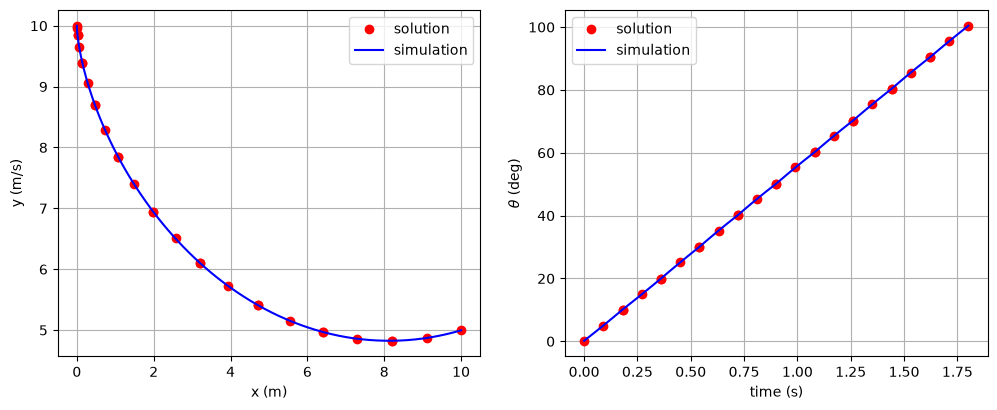

In [4]:
import numpy as np
import openmdao.api as om
import dymos as dm

import matplotlib.pyplot as plt
from dymos.examples.brachistochrone.brachistochrone_ode import BrachistochroneODE

#
# Define the OpenMDAO problem
#
p = om.Problem(model=om.Group())

# Instantiate the transcription so we can get the number of nodes from it while
# building the problem.
tx = dm.GaussLobatto(num_segments=10, order=3)

# Add an indep var comp to provide the external control values
ivc = p.model.add_subsystem('control_ivc', om.IndepVarComp(), promotes_outputs=['*'])

# Add the output to provide the values of theta at the control input nodes of the transcription.
ivc.add_output('theta', shape=(tx.grid_data.subset_num_nodes['control_input']), units='rad')

# Add this external control as a design variable
p.model.add_design_var('theta', units='rad', lower=1.0E-5, upper=np.pi)
# Connect this to controls:theta in the appropriate phase.
# connect calls are cached, so we can do this before we actually add the trajectory to the problem.
p.model.connect('theta', 'traj.phase0.controls:theta')

#
# Define a Trajectory object
#
traj = dm.Trajectory()

p.model.add_subsystem('traj', subsys=traj)

#
# Define a Dymos Phase object with GaussLobatto Transcription
#
phase = dm.Phase(ode_class=BrachistochroneODE,
                 transcription=tx)

traj.add_phase(name='phase0', phase=phase)

#
# Set the time options
# Time has no targets in our ODE.
# We fix the initial time so that the it is not a design variable in the optimization.
# The duration of the phase is allowed to be optimized, but is bounded on [0.5, 10].
#
phase.set_time_options(fix_initial=True, duration_bounds=(0.5, 10.0), units='s')

#
# Set the time options
# Initial values of positions and velocity are all fixed.
# The final value of position are fixed, but the final velocity is a free variable.
# The equations of motion are not functions of position, so 'x' and 'y' have no targets.
# The rate source points to the output in the ODE which provides the time derivative of the
# given state.
phase.add_state('x', fix_initial=True, fix_final=True, units='m', rate_source='xdot')
phase.add_state('y', fix_initial=True, fix_final=True, units='m', rate_source='ydot')
phase.add_state('v', fix_initial=True, fix_final=False, units='m/s',
                rate_source='vdot', targets=['v'])

# Define theta as a control.
# Use opt=False to allow it to be connected to an external source.
# Arguments lower and upper are no longer valid for an input control.
phase.add_control(name='theta', targets=['theta'], opt=False)

# Minimize final time.
phase.add_objective('time', loc='final')

# Set the driver.
p.driver = om.ScipyOptimizeDriver()

# Allow OpenMDAO to automatically determine our sparsity pattern.
# Doing so can significant speed up the execution of Dymos.
p.driver.declare_coloring()

# Setup the problem
p.setup(check=True)

# Now that the OpenMDAO problem is setup, we can set the values of the states and controls.
phase.set_state_val('x', [0, 10])

phase.set_state_val('y', [10, 5])

phase.set_state_val('v', [0, 5])

phase.set_control_val('theta', [90, 90.5], units='deg')

# Run the driver to solve the problem
p.run_driver()

# Test the results
print(p.get_val('traj.phase0.timeseries.time')[-1])

# Check the validity of our results.
sim_out = traj.simulate()

# Plot the results
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 4.5))

axes[0].plot(p.get_val('traj.phase0.timeseries.x'),
             p.get_val('traj.phase0.timeseries.y'),
             'ro', label='solution')

axes[0].plot(sim_out.get_val('traj.phase0.timeseries.x'),
             sim_out.get_val('traj.phase0.timeseries.y'),
             'b-', label='simulation')

axes[0].set_xlabel('x (m)')
axes[0].set_ylabel('y (m/s)')
axes[0].legend()
axes[0].grid()

axes[1].plot(p.get_val('traj.phase0.timeseries.time'),
             p.get_val('traj.phase0.timeseries.theta', units='deg'),
             'ro', label='solution')

axes[1].plot(sim_out.get_val('traj.phase0.timeseries.time'),
             sim_out.get_val('traj.phase0.timeseries.theta', units='deg'),
             'b-', label='simulation')

axes[1].set_xlabel('time (s)')
axes[1].set_ylabel(r'$\theta$ (deg)')
axes[1].legend()
axes[1].grid()

plt.show()

In [5]:
from openmdao.utils.assert_utils import assert_near_equal

assert_near_equal(p.get_val('traj.phase0.timeseries.time')[-1], 1.8016,
                  tolerance=1.0E-3)

np.float64(2.521948378249477e-06)